# Phase 03 — Psychological Capital → Employability

## Step 05 — Multiple Linear Regression

මෙම notebook එකේ අරමුණ වන්නේ Psychological Capital සහ Employability අතර predictive relationship එක regression analysis මගින් පරීක්ෂා කිරීමයි.

මෙහිදී regression approaches දෙකක් භාවිත කරයි:

1. Overall Psychological Capital (`PsyCap_avg`) භාවිත කරන Simple Linear Regression
2. Hope, Optimism, Resilience සහ Self-Efficacy constructs එකවර භාවිත කරන Multiple Linear Regression

අමතරව පහත diagnostics සහ validation methods භාවිත කරයි:

- R² සහ Adjusted R²
- Regression coefficients සහ p-values
- 95% confidence intervals
- Standardized coefficients
- Variance Inflation Factor (VIF)
- Train/Test validation
- MAE, RMSE සහ MAPE
- Residual diagnostics
- Breusch-Pagan heteroscedasticity test
- HC3 robust standard errors

මෙම analysis එක Step 06 feature representation comparison සහ පසුව machine-learning experiments සඳහා statistical foundation එකක් සපයයි.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.api as sm

from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

from statsmodels.stats.diagnostic import (
    het_breuschpagan
)

from sklearn.model_selection import (
    train_test_split
)

from sklearn.preprocessing import (
    StandardScaler
)

from sklearn.linear_model import (
    LinearRegression
)

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

In [3]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "phase3_psycap":
    PROJECT_DIR = PROJECT_DIR.parent.parent

DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "phase3_psycap_prepared.csv"
)

REPORT_DIR = (
    PROJECT_DIR
    / "reports"
    / "phase3"
    / "regression"
)

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("PROJECT_DIR:", PROJECT_DIR)
print("DATA_PATH:", DATA_PATH)
print("REPORT_DIR:", REPORT_DIR)

PROJECT_DIR: d:\internship-employability-project
DATA_PATH: d:\internship-employability-project\data\processed\phase3_psycap_prepared.csv
REPORT_DIR: d:\internship-employability-project\reports\phase3\regression


In [4]:
df = pd.read_csv(
    DATA_PATH
)

print(
    "Dataset shape:",
    df.shape
)

df.head()

Dataset shape: (1000, 41)


,Response_ID,Gender,Age,Degree Program,Internship Status,PsyCap1,PsyCap2,PsyCap3,PsyCap4,PsyCap5,...,Optimism_avg,Resilience_avg,SelfEfficacy_avg,PsyCap_avg,HumanCapital_avg,SocialCapital_avg,CareerIdentity_avg,EnvironmentalMonitoring_avg,Balance_avg,EVS_avg
0,1,Female,18–20,Information Technology,Yes,5,4,4,4,5,...,4.333333,4.000000,3.666667,4.083333,5.000000,4.0,4.75,5.0,5.0,4.750000
1,2,Female,21–23,Business Management,Yes,3,5,5,4,4,...,4.000000,3.666667,3.666667,3.916667,3.666667,3.5,3.75,4.0,2.5,3.500000
2,3,Male,18–20,Information Technology,Yes,4,5,4,5,4,...,4.333333,3.333333,3.333333,3.833333,3.666667,4.0,3.75,4.0,3.5,3.750000
3,4,Male,18–20,Engineering,Yes,4,4,4,4,4,...,4.000000,4.000000,4.000000,4.000000,4.000000,4.0,4.00,4.0,4.0,4.000000
4,5,Male,21–23,Business Management,Yes,3,3,5,3,5,...,4.000000,3.666667,3.333333,3.666667,4.000000,4.5,4.50,5.0,4.0,4.333333


## Regression Variables

Multiple regression model එක සඳහා predictors ලෙස Psychological Capital constructs හතර භාවිත කරයි:

- Hope
- Optimism
- Resilience
- Self-Efficacy

Target variable එක:

- Employability (`EVS_avg`)

Overall Psychological Capital (`PsyCap_avg`) භාවිත කර simple regression model එකක්ද පරීක්ෂා කරයි.

In [5]:
PREDICTORS = [
    "Hope_avg",
    "Optimism_avg",
    "Resilience_avg",
    "SelfEfficacy_avg"
]

OVERALL_PSYCAP = "PsyCap_avg"

TARGET = "EVS_avg"

Validate Required Columns

In [6]:
required_columns = (
    PREDICTORS
    +
    [OVERALL_PSYCAP, TARGET]
)

missing_columns = [
    column
    for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required regression columns: {missing_columns}"
    )

print(
    "All required regression columns are available."
)

All required regression columns are available.


Check Missing Values

In [7]:
regression_missing = (
    df[required_columns]
    .isnull()
    .sum()
)

regression_missing

Hope_avg            0
Optimism_avg        0
Resilience_avg      0
SelfEfficacy_avg    0
PsyCap_avg          0
EVS_avg             0
dtype: int64

Simple Linear Regression

## Model A — Overall Psychological Capital Regression

මෙම model එකෙන් overall Psychological Capital score එක Employability predict කරන ප්‍රමාණය පරීක්ෂා කරයි.

Model structure:

`EVS_avg = β0 + β1(PsyCap_avg)`

Fit Full-Sample OLS Simple Regression

In [8]:
X_simple = df[
    [OVERALL_PSYCAP]
].copy()

y = df[
    TARGET
].copy()

X_simple_ols = sm.add_constant(
    X_simple
)

simple_ols_model = sm.OLS(
    y,
    X_simple_ols
).fit()

print(
    simple_ols_model.summary()
)

                            OLS Regression Results                            
Dep. Variable:                EVS_avg   R-squared:                       0.570
Model:                            OLS   Adj. R-squared:                  0.570
Method:                 Least Squares   F-statistic:                     1325.
Date:                Thu, 27 Aug 2026   Prob (F-statistic):          2.90e-185
Time:                        17:15:08   Log-Likelihood:                 33.349
No. Observations:                1000   AIC:                            -62.70
Df Residuals:                     998   BIC:                            -52.88
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.9493      0.086     10.984      0.0

Extract Simple Regression Results

In [9]:
simple_regression_summary = pd.DataFrame({
    "Metric": [
        "R2",
        "Adjusted_R2",
        "F_Statistic",
        "F_P_Value"
    ],
    "Value": [
        simple_ols_model.rsquared,
        simple_ols_model.rsquared_adj,
        simple_ols_model.fvalue,
        simple_ols_model.f_pvalue
    ]
})

simple_regression_summary

,Metric,Value
0,R2,5.703220e-01
1,Adjusted_R2,5.698914e-01
2,F_Statistic,1.324669e+03
3,F_P_Value,2.899396e-185


## Model B — Multiple Linear Regression

මෙම model එකෙන් Hope, Optimism, Resilience සහ Self-Efficacy constructs එකවර සලකා Employability predict කරයි.

මෙහි අරමුණ correlation strength පමණක් නොව, අනෙක් constructs control කළ පසු එක් එක් construct එකේ unique contribution එක පරීක්ෂා කිරීමයි.

Fit Full-Sample Multiple OLS

In [10]:
X_multiple = df[
    PREDICTORS
].copy()

X_multiple_ols = sm.add_constant(
    X_multiple
)

multiple_ols_model = sm.OLS(
    y,
    X_multiple_ols
).fit()

print(
    multiple_ols_model.summary()
)

                            OLS Regression Results                            
Dep. Variable:                EVS_avg   R-squared:                       0.599
Model:                            OLS   Adj. R-squared:                  0.597
Method:                 Least Squares   F-statistic:                     371.5
Date:                Thu, 27 Aug 2026   Prob (F-statistic):          1.17e-195
Time:                        17:15:43   Log-Likelihood:                 67.820
No. Observations:                1000   AIC:                            -125.6
Df Residuals:                     995   BIC:                            -101.1
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                1.0186      0.085  

Extract Multiple Regression Coefficients

In [11]:
confidence_intervals = (
    multiple_ols_model
    .conf_int()
)

coefficient_table = pd.DataFrame({
    "Variable": (
        multiple_ols_model
        .params
        .index
    ),
    "Coefficient": (
        multiple_ols_model
        .params
        .values
    ),
    "Std_Error": (
        multiple_ols_model
        .bse
        .values
    ),
    "t_Value": (
        multiple_ols_model
        .tvalues
        .values
    ),
    "P_Value": (
        multiple_ols_model
        .pvalues
        .values
    ),
    "CI_95_Lower": (
        confidence_intervals[
            0
        ]
        .values
    ),
    "CI_95_Upper": (
        confidence_intervals[
            1
        ]
        .values
    )
})

coefficient_table

,Variable,Coefficient,Std_Error,t_Value,P_Value,CI_95_Lower,CI_95_Upper
0,const,1.018636,0.084669,12.030744,3.194592e-31,0.852485,1.184787
1,Hope_avg,0.057392,0.026648,2.153672,3.150553e-02,0.005098,0.109685
2,Optimism_avg,0.075479,0.027470,2.747682,6.110310e-03,0.021573,0.129385
3,Resilience_avg,0.267860,0.026381,10.153607,4.083120e-23,0.216092,0.319628
4,SelfEfficacy_avg,0.335765,0.026093,12.868191,3.650633e-35,0.284562,0.386968


Add Significance Decision

In [12]:
coefficient_table[
    "Significance"
] = np.where(
    coefficient_table[
        "P_Value"
    ] < 0.05,
    "Significant",
    "Not Significant"
)

coefficient_table

,Variable,Coefficient,Std_Error,t_Value,P_Value,CI_95_Lower,CI_95_Upper,Significance
0,const,1.018636,0.084669,12.030744,3.194592e-31,0.852485,1.184787,Significant
1,Hope_avg,0.057392,0.026648,2.153672,3.150553e-02,0.005098,0.109685,Significant
2,Optimism_avg,0.075479,0.027470,2.747682,6.110310e-03,0.021573,0.129385,Significant
3,Resilience_avg,0.267860,0.026381,10.153607,4.083120e-23,0.216092,0.319628,Significant
4,SelfEfficacy_avg,0.335765,0.026093,12.868191,3.650633e-35,0.284562,0.386968,Significant


Overall Multiple Regression Summary

In [13]:
multiple_regression_summary = pd.DataFrame({
    "Metric": [
        "R2",
        "Adjusted_R2",
        "F_Statistic",
        "F_P_Value",
        "AIC",
        "BIC"
    ],
    "Value": [
        multiple_ols_model.rsquared,
        multiple_ols_model.rsquared_adj,
        multiple_ols_model.fvalue,
        multiple_ols_model.f_pvalue,
        multiple_ols_model.aic,
        multiple_ols_model.bic
    ]
})

multiple_regression_summary

,Metric,Value
0,R2,5.989463e-01
1,Adjusted_R2,5.973340e-01
2,F_Statistic,3.714911e+02
3,F_P_Value,1.171941e-195
4,AIC,-1.256396e+02
5,BIC,-1.011008e+02


Standardized Coefficients

## Standardized Regression Coefficients

Predictors සියල්ල standardized කිරීමෙන් එක් එක් Psychological Capital construct එකේ relative unique contribution එක එකම scale එකක compare කළ හැක.

Standardized coefficient එක විශාල වීම එම predictor එක regression prediction තුළ වැඩි relative contribution එකක් ඇති බව පෙන්වයි.

Standardize Predictors and Target

In [14]:
x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_standardized = x_scaler.fit_transform(
    X_multiple
)

y_standardized = (
    y_scaler
    .fit_transform(
        y.to_numpy()
        .reshape(-1, 1)
    )
    .ravel()
)

Fit Standardized Regression

In [15]:
standardized_model = LinearRegression()

standardized_model.fit(
    X_standardized,
    y_standardized
)

standardized_coefficients = pd.DataFrame({
    "Predictor": PREDICTORS,
    "Standardized_Beta": (
        standardized_model
        .coef_
    )
})

standardized_coefficients[
    "Absolute_Beta"
] = (
    standardized_coefficients[
        "Standardized_Beta"
    ]
    .abs()
)

standardized_coefficients = (
    standardized_coefficients
    .sort_values(
        "Absolute_Beta",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

standardized_coefficients[
    "Rank"
] = np.arange(
    1,
    len(
        standardized_coefficients
    ) + 1
)

standardized_coefficients

,Predictor,Standardized_Beta,Absolute_Beta,Rank
0,SelfEfficacy_avg,0.404306,0.404306,1
1,Resilience_avg,0.310952,0.310952,2
2,Optimism_avg,0.089824,0.089824,3
3,Hope_avg,0.063732,0.063732,4


Multicollinearity

## Multicollinearity Analysis

Psychological Capital constructs අතර correlations පවතින බැවින් multiple regression coefficients unstable වීමේ අවදානම පරීක්ෂා කිරීමට Variance Inflation Factor (VIF) භාවිත කරයි.

VIF calculation සඳහා intercept එක ඇතුළත් කරයි.

Correct VIF Calculation

In [16]:
X_vif = sm.add_constant(
    X_multiple
)

vif_results = []

for i, column in enumerate(
    X_vif.columns
):

    if column == "const":
        continue

    vif_value = variance_inflation_factor(
        X_vif.values,
        i
    )

    vif_results.append({
        "Predictor": column,
        "VIF": vif_value,
        "Tolerance": (
            1 / vif_value
        )
    })


vif_df = pd.DataFrame(
    vif_results
)

vif_df

,Predictor,VIF,Tolerance
0,Hope_avg,2.172600,0.460278
1,Optimism_avg,2.651413,0.377157
2,Resilience_avg,2.326840,0.429767
3,SelfEfficacy_avg,2.449093,0.408314


Add VIF Status

In [17]:
vif_df[
    "Status"
] = np.where(
    vif_df[
        "VIF"
    ] < 5,
    "Acceptable",
    "Review"
)

vif_df

,Predictor,VIF,Tolerance,Status
0,Hope_avg,2.172600,0.460278,Acceptable
1,Optimism_avg,2.651413,0.377157,Acceptable
2,Resilience_avg,2.326840,0.429767,Acceptable
3,SelfEfficacy_avg,2.449093,0.408314,Acceptable


## Train/Test Predictive Validation

Full-sample OLS analysis statistical inference සඳහා භාවිත කළත්, actual predictive generalization එක පරීක්ෂා කිරීම සඳහා independent train/test split එකක් භාවිත කරයි.

80% data training සඳහා සහ 20% data testing සඳහා භාවිත කරයි.

`random_state = 42` භාවිත කිරීමෙන් split එක reproducible වේ.

Split Data

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X_multiple,
    y,
    test_size=0.20,
    random_state=42
)

print(
    "Training rows:",
    len(X_train)
)

print(
    "Testing rows:",
    len(X_test)
)

Training rows: 800
Testing rows: 200


Fit Multiple Regression on Training Data

In [19]:
train_model = LinearRegression()

train_model.fit(
    X_train,
    y_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[0. ,0.16,0.22,0.36]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['Hope_avg','Optimism_avg','Resilience_avg','SelfEfficacy_avg']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.9725
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


Predictions

In [20]:
train_predictions = (
    train_model.predict(
        X_train
    )
)

test_predictions = (
    train_model.predict(
        X_test
    )
)

Evaluation Function

In [21]:
def regression_metrics(
    y_true,
    y_pred
):

    r2 = r2_score(
        y_true,
        y_pred
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    mape = (
        mean_absolute_percentage_error(
            y_true,
            y_pred
        )
        * 100
    )

    return {
        "R2": r2,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE_Percent": mape
    }

Calculate Train/Test Metrics

In [22]:
train_metrics = regression_metrics(
    y_train,
    train_predictions
)

test_metrics = regression_metrics(
    y_test,
    test_predictions
)

train_test_metrics = pd.DataFrame([
    {
        "Dataset": "Train",
        **train_metrics
    },
    {
        "Dataset": "Test",
        **test_metrics
    }
])

train_test_metrics

,Dataset,R2,MAE,RMSE,MAPE_Percent
0,Train,0.648287,0.131245,0.209561,3.431886
1,Test,0.396405,0.154939,0.288374,4.269091


Train/Test Gap

In [23]:
train_test_r2_gap = (
    train_metrics[
        "R2"
    ]
    -
    test_metrics[
        "R2"
    ]
)

print(
    "Train-Test R² Gap:",
    train_test_r2_gap
)

Train-Test R² Gap: 0.2518821038116261


Train/Test Split for Overall PsyCap Model

In [24]:
X_simple_train = (
    df.loc[
        X_train.index,
        [OVERALL_PSYCAP]
    ]
)

X_simple_test = (
    df.loc[
        X_test.index,
        [OVERALL_PSYCAP]
    ]
)

y_simple_train = (
    y.loc[
        X_train.index
    ]
)

y_simple_test = (
    y.loc[
        X_test.index
    ]
)

Fit Simple Prediction Model

In [25]:
simple_prediction_model = (
    LinearRegression()
)

simple_prediction_model.fit(
    X_simple_train,
    y_simple_train
)

simple_test_predictions = (
    simple_prediction_model.predict(
        X_simple_test
    )
)

simple_test_metrics = (
    regression_metrics(
        y_simple_test,
        simple_test_predictions
    )
)

simple_test_metrics

{'R2': 0.392533011117997,
 'MAE': 0.16146961482297115,
 'RMSE': np.float64(0.2892971054574308),
 'MAPE_Percent': 4.396092022595036}

Compare Simple vs Multiple Models

In [26]:
model_comparison = pd.DataFrame([
    {
        "Model":
            "Overall PsyCap",

        **simple_test_metrics
    },

    {
        "Model":
            "Four PsyCap Constructs",

        **test_metrics
    }
])

model_comparison

,Model,R2,MAE,RMSE,MAPE_Percent
0,Overall PsyCap,0.392533,0.161470,0.289297,4.396092
1,Four PsyCap Constructs,0.396405,0.154939,0.288374,4.269091


## Residual Diagnostics

Regression residuals භාවිත කර prediction errors වල systematic patterns පවතිනවද යන්න පරීක්ෂා කරයි.

Residual diagnostics මගින්:

- systematic prediction bias
- heteroscedasticity
- unusual error patterns

වැනි issues හඳුනා ගත හැක.

Calculate Residuals

In [27]:
residuals = (
    y_test.to_numpy()
    -
    test_predictions
)

fitted_values = (
    test_predictions
)

Residual Summary

In [28]:
residual_summary = pd.DataFrame({
    "Metric": [
        "Mean_Residual",
        "Residual_Std",
        "Minimum_Residual",
        "Maximum_Residual"
    ],
    "Value": [
        residuals.mean(),
        residuals.std(),
        residuals.min(),
        residuals.max()
    ]
})

residual_summary

,Metric,Value
0,Mean_Residual,0.018209
1,Residual_Std,0.287798
2,Minimum_Residual,-1.424152
3,Maximum_Residual,1.593404


Residual Histogram

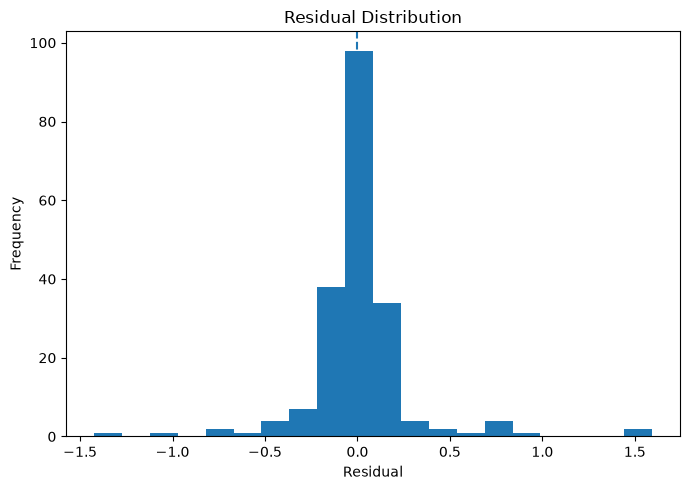

In [29]:
plt.figure(
    figsize=(7, 5)
)

plt.hist(
    residuals,
    bins=20
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Residual"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "Residual Distribution"
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR
    / "Residual_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Residual vs Fitted Plot

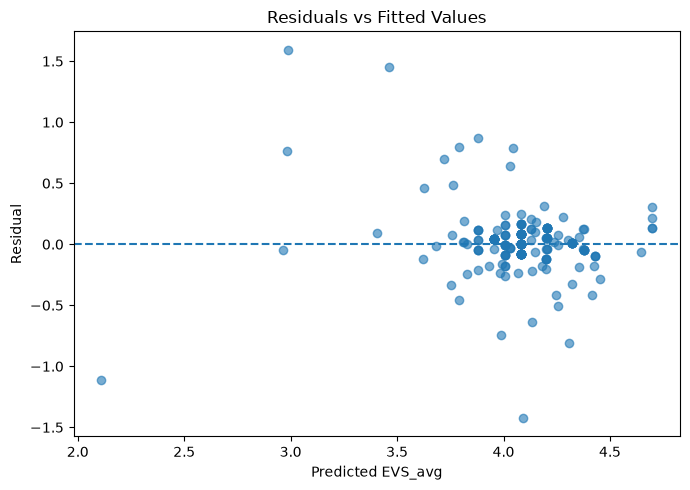

In [30]:
plt.figure(
    figsize=(7, 5)
)

plt.scatter(
    fitted_values,
    residuals,
    alpha=0.6
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Predicted EVS_avg"
)

plt.ylabel(
    "Residual"
)

plt.title(
    "Residuals vs Fitted Values"
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR
    / "Residuals_vs_Fitted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Actual vs Predicted Plot

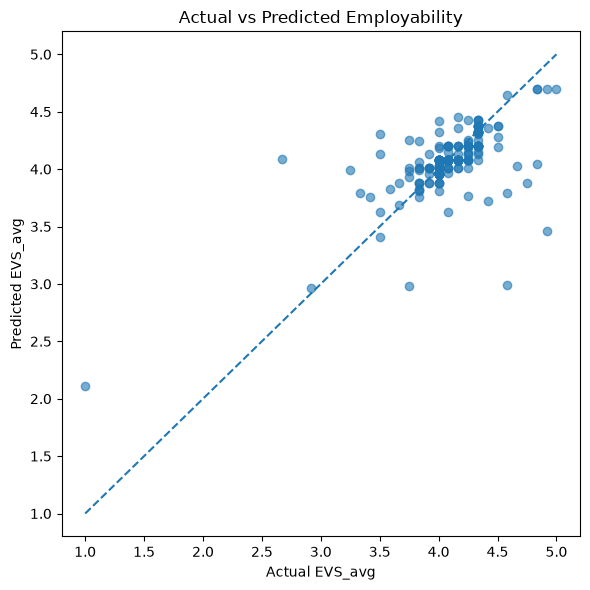

In [31]:
plt.figure(
    figsize=(6, 6)
)

plt.scatter(
    y_test,
    test_predictions,
    alpha=0.6
)

minimum = min(
    y_test.min(),
    test_predictions.min()
)

maximum = max(
    y_test.max(),
    test_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel(
    "Actual EVS_avg"
)

plt.ylabel(
    "Predicted EVS_avg"
)

plt.title(
    "Actual vs Predicted Employability"
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR
    / "Actual_vs_Predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

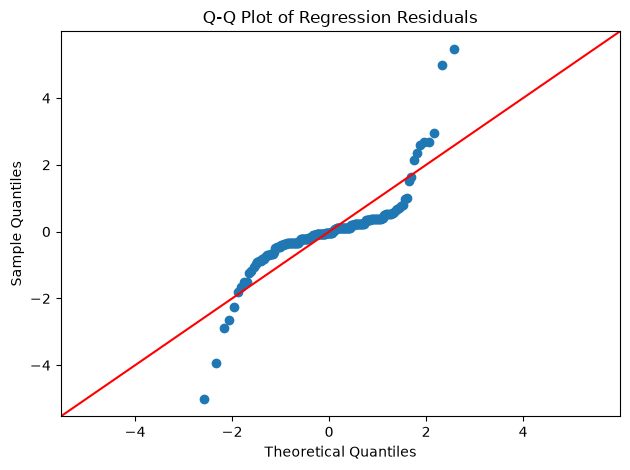

In [32]:
sm.qqplot(
    residuals,
    line="45",
    fit=True
)

plt.title(
    "Q-Q Plot of Regression Residuals"
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR
    / "Residual_QQ_Plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Actual vs Predicted Plot

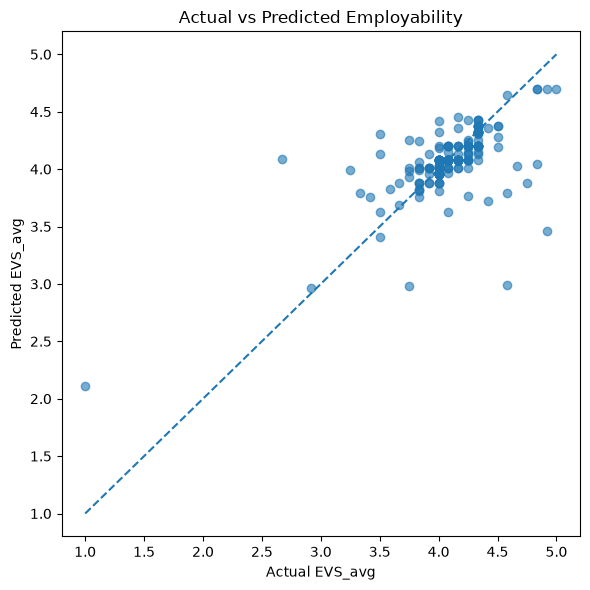

In [33]:
plt.figure(
    figsize=(6, 6)
)

plt.scatter(
    y_test,
    test_predictions,
    alpha=0.6
)

minimum = min(
    y_test.min(),
    test_predictions.min()
)

maximum = max(
    y_test.max(),
    test_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel(
    "Actual EVS_avg"
)

plt.ylabel(
    "Predicted EVS_avg"
)

plt.title(
    "Actual vs Predicted Employability"
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR
    / "Actual_vs_Predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Q-Q Plot

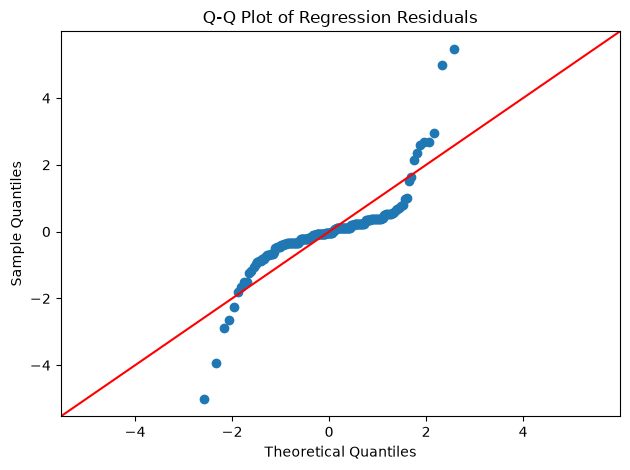

In [34]:
sm.qqplot(
    residuals,
    line="45",
    fit=True
)

plt.title(
    "Q-Q Plot of Regression Residuals"
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR
    / "Residual_QQ_Plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Heteroscedasticity Check

Breusch-Pagan test එක residual variance fitted values සමඟ systematically වෙනස් වෙනවද යන්න පරීක්ෂා කරයි.

Significant result එකක් ලැබුණොත් robust standard errors භාවිත කිරීම වඩා සුදුසු වේ.

Breusch-Pagan Test

In [35]:
bp_test = het_breuschpagan(
    multiple_ols_model.resid,
    multiple_ols_model.model.exog
)

bp_results = pd.DataFrame({
    "Statistic": [
        "LM Statistic",
        "LM P-Value",
        "F Statistic",
        "F P-Value"
    ],
    "Value": [
        bp_test[0],
        bp_test[1],
        bp_test[2],
        bp_test[3]
    ]
})

bp_results

,Statistic,Value
0,LM Statistic,1.215477e+02
1,LM P-Value,2.494954e-25
2,F Statistic,3.441847e+01
3,F P-Value,6.144210e-27


Interpret Breusch-Pagan

In [36]:
bp_p_value = (
    bp_test[
        1
    ]
)

if bp_p_value < 0.05:

    heteroscedasticity_status = (
        "Evidence of heteroscedasticity"
    )

else:

    heteroscedasticity_status = (
        "No strong evidence of heteroscedasticity"
    )


print(
    heteroscedasticity_status
)

Evidence of heteroscedasticity


HC3 Robust Standard Errors

## HC3 Robust Standard Errors

Distribution skewness සහ potential heteroscedasticity නිසා regression inference එක වඩා robust කිරීමට HC3 robust standard errors ගණනය කරයි.

Robust standard errors regression predictions වෙනස් නොකරයි. ඒවා coefficients සඳහා standard errors, p-values සහ confidence intervals වඩා defensible ලෙස estimate කිරීමට උපකාරී වේ.

Fit Robust HC3 Inference

In [38]:
robust_ols_model = (
    multiple_ols_model
    .get_robustcov_results(
        cov_type="HC3"
    )
)

print(
    robust_ols_model.summary()
)

                            OLS Regression Results                            
Dep. Variable:                EVS_avg   R-squared:                       0.599
Model:                            OLS   Adj. R-squared:                  0.597
Method:                 Least Squares   F-statistic:                     56.88
Date:                Thu, 27 Aug 2026   Prob (F-statistic):           3.02e-43
Time:                        19:53:28   Log-Likelihood:                 67.820
No. Observations:                1000   AIC:                            -125.6
Df Residuals:                     995   BIC:                            -101.1
Df Model:                           4                                         
Covariance Type:                  HC3                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                1.0186      0.239  

Robust Coefficient Table

In [39]:
robust_conf_int = (
    robust_ols_model
    .conf_int()
)

robust_coefficient_table = pd.DataFrame({
    "Variable": (
        multiple_ols_model
        .params
        .index
    ),
    "Coefficient": (
        robust_ols_model
        .params
    ),
    "Robust_Std_Error": (
        robust_ols_model
        .bse
    ),
    "Robust_t": (
        robust_ols_model
        .tvalues
    ),
    "Robust_P_Value": (
        robust_ols_model
        .pvalues
    ),
    "Robust_CI_Lower": (
        robust_conf_int[
            :,
            0
        ]
    ),
    "Robust_CI_Upper": (
        robust_conf_int[
            :,
            1
        ]
    )
})

robust_coefficient_table[
    "Robust_Significance"
] = np.where(
    robust_coefficient_table[
        "Robust_P_Value"
    ] < 0.05,
    "Significant",
    "Not Significant"
)

robust_coefficient_table

,Variable,Coefficient,Robust_Std_Error,Robust_t,Robust_P_Value,Robust_CI_Lower,Robust_CI_Upper,Robust_Significance
0,const,1.018636,0.238894,4.263972,2.199435e-05,0.549843,1.487430,Significant
1,Hope_avg,0.057392,0.045667,1.256743,2.091417e-01,-0.032223,0.147007,Not Significant
2,Optimism_avg,0.075479,0.063280,1.192781,2.332396e-01,-0.048698,0.199657,Not Significant
3,Resilience_avg,0.267860,0.048664,5.504310,4.715522e-08,0.172365,0.363355,Significant
4,SelfEfficacy_avg,0.335765,0.054743,6.133494,1.238678e-09,0.228340,0.443190,Significant


Prediction Range Check

In [40]:
prediction_range_check = {
    "Minimum_Prediction": float(
        test_predictions.min()
    ),
    "Maximum_Prediction": float(
        test_predictions.max()
    ),
    "Below_1": int(
        np.sum(
            test_predictions < 1
        )
    ),
    "Above_5": int(
        np.sum(
            test_predictions > 5
        )
    )
}

prediction_range_check

{'Minimum_Prediction': 2.110015713937452,
 'Maximum_Prediction': 4.6996155188399715,
 'Below_1': 0,
 'Above_5': 0}

Sinhala explanation

EVS range 1–5.

Test predictions range එක valid ද check කරනවා.

Final Regression Evidence Table

## Final Regression Evidence

Overall PsyCap simple regression සහ four-construct multiple regression results එකට compare කර final statistical and predictive evidence සාරාංශ කරයි.

Build Final Evidence

In [41]:
final_regression_evidence = pd.DataFrame([
    {
        "Model":
            "Overall PsyCap",

        "Full_Sample_R2":
            simple_ols_model.rsquared,

        "Adjusted_R2":
            simple_ols_model.rsquared_adj,

        "Test_R2":
            simple_test_metrics[
                "R2"
            ],

        "Test_MAE":
            simple_test_metrics[
                "MAE"
            ],

        "Test_RMSE":
            simple_test_metrics[
                "RMSE"
            ],

        "Test_MAPE":
            simple_test_metrics[
                "MAPE_Percent"
            ]
    },

    {
        "Model":
            "Four PsyCap Constructs",

        "Full_Sample_R2":
            multiple_ols_model.rsquared,

        "Adjusted_R2":
            multiple_ols_model.rsquared_adj,

        "Test_R2":
            test_metrics[
                "R2"
            ],

        "Test_MAE":
            test_metrics[
                "MAE"
            ],

        "Test_RMSE":
            test_metrics[
                "RMSE"
            ],

        "Test_MAPE":
            test_metrics[
                "MAPE_Percent"
            ]
    }
])

final_regression_evidence


,Model,Full_Sample_R2,Adjusted_R2,Test_R2,Test_MAE,Test_RMSE,Test_MAPE
0,Overall PsyCap,0.570322,0.569891,0.392533,0.161470,0.289297,4.396092
1,Four PsyCap Constructs,0.598946,0.597334,0.396405,0.154939,0.288374,4.269091


Final Validation Summary

In [42]:
all_vif_acceptable = bool(
    (
        vif_df[
            "VIF"
        ] < 5
    )
    .all()
)

prediction_range_valid = bool(
    prediction_range_check[
        "Below_1"
    ] == 0
    and
    prediction_range_check[
        "Above_5"
    ] == 0
)

step05_validation_summary = pd.DataFrame({

    "Regression_Check": [

        "Required variables available",

        "Simple regression completed",

        "Multiple regression completed",

        "Standardized coefficients calculated",

        "VIF reviewed",

        "No severe multicollinearity",

        "Train-test validation completed",

        "Residual diagnostics completed",

        "Breusch-Pagan test completed",

        "HC3 robust inference completed",

        "Prediction range reviewed"
    ],

    "Status": [

        (
            "PASS"
            if len(
                missing_columns
            ) == 0
            else "FAIL"
        ),

        "PASS",

        "PASS",

        "PASS",

        "PASS",

        (
            "PASS"
            if all_vif_acceptable
            else "REVIEW"
        ),

        "PASS",

        "PASS",

        "PASS",

        "PASS",

        (
            "PASS"
            if prediction_range_valid
            else "REVIEW"
        )
    ]
})

step05_validation_summary

,Regression_Check,Status
0,Required variables available,PASS
1,Simple regression completed,PASS
2,Multiple regression completed,PASS
3,Standardized coefficients calculated,PASS
4,VIF reviewed,PASS
5,No severe multicollinearity,PASS
6,Train-test validation completed,PASS
7,Residual diagnostics completed,PASS
8,Breusch-Pagan test completed,PASS
9,HC3 robust inference completed,PASS


Save Everything

In [43]:
simple_regression_summary.to_csv(
    REPORT_DIR
    / "Simple_Regression_Summary.csv",
    index=False
)

multiple_regression_summary.to_csv(
    REPORT_DIR
    / "Multiple_Regression_Summary.csv",
    index=False
)

coefficient_table.to_csv(
    REPORT_DIR
    / "Multiple_Regression_Coefficients.csv",
    index=False
)

standardized_coefficients.to_csv(
    REPORT_DIR
    / "Standardized_Coefficients.csv",
    index=False
)

vif_df.to_csv(
    REPORT_DIR
    / "VIF_Analysis.csv",
    index=False
)

train_test_metrics.to_csv(
    REPORT_DIR
    / "Train_Test_Regression_Metrics.csv",
    index=False
)

model_comparison.to_csv(
    REPORT_DIR
    / "Overall_vs_Construct_Regression.csv",
    index=False
)

residual_summary.to_csv(
    REPORT_DIR
    / "Residual_Summary.csv",
    index=False
)

bp_results.to_csv(
    REPORT_DIR
    / "Breusch_Pagan_Test.csv",
    index=False
)

robust_coefficient_table.to_csv(
    REPORT_DIR
    / "HC3_Robust_Coefficients.csv",
    index=False
)

final_regression_evidence.to_csv(
    REPORT_DIR
    / "Final_Regression_Evidence.csv",
    index=False
)

step05_validation_summary.to_csv(
    REPORT_DIR
    / "Step05_Validation_Summary.csv",
    index=False
)

print(
    "Step 05 regression reports saved successfully."
)

Step 05 regression reports saved successfully.


Final Overview

In [44]:
print(
    "PHASE 03 — STEP 05 MULTIPLE LINEAR REGRESSION"
)

print(
    "\nModel Comparison:"
)

print(
    final_regression_evidence
    .to_string(
        index=False
    )
)

print(
    "\nStandardized Coefficients:"
)

print(
    standardized_coefficients
    .to_string(
        index=False
    )
)

print(
    "\nVIF:"
)

print(
    vif_df
    .to_string(
        index=False
    )
)

print(
    "\nBreusch-Pagan:"
)

print(
    bp_results
    .to_string(
        index=False
    )
)

print(
    "\nValidation:"
)

print(
    step05_validation_summary
    .to_string(
        index=False
    )
)

PHASE 03 — STEP 05 MULTIPLE LINEAR REGRESSION

Model Comparison:
                 Model  Full_Sample_R2  Adjusted_R2  Test_R2  Test_MAE  Test_RMSE  Test_MAPE
        Overall PsyCap        0.570322     0.569891 0.392533  0.161470   0.289297   4.396092
Four PsyCap Constructs        0.598946     0.597334 0.396405  0.154939   0.288374   4.269091

Standardized Coefficients:
       Predictor  Standardized_Beta  Absolute_Beta  Rank
SelfEfficacy_avg           0.404306       0.404306     1
  Resilience_avg           0.310952       0.310952     2
    Optimism_avg           0.089824       0.089824     3
        Hope_avg           0.063732       0.063732     4

VIF:
       Predictor      VIF  Tolerance     Status
        Hope_avg 2.172600   0.460278 Acceptable
    Optimism_avg 2.651413   0.377157 Acceptable
  Resilience_avg 2.326840   0.429767 Acceptable
SelfEfficacy_avg 2.449093   0.408314 Acceptable

Breusch-Pagan:
   Statistic        Value
LM Statistic 1.215477e+02
  LM P-Value 2.494954e-25
 F 

## Step 05 අවසාන නිගමනය

Psychological Capital සහ Employability අතර predictive relationship එක Simple Linear Regression සහ Multiple Linear Regression approaches දෙකක් භාවිත කර පරීක්ෂා කරන ලදී.

Overall Psychological Capital score එක Employability predict කරන ආකාරය simple regression model එකෙන් පරීක්ෂා කළ අතර, Hope, Optimism, Resilience සහ Self-Efficacy constructs එකවර multiple regression model එකට ඇතුළත් කර එක් එක් construct එකේ unique contribution එක පරීක්ෂා කරන ලදී.

Regression coefficients, p-values, confidence intervals සහ standardized coefficients භාවිත කර statistical contribution සහ relative predictor strength විශ්ලේෂණය කරන ලදී.

Variance Inflation Factor (VIF) භාවිත කර multicollinearity පරීක්ෂා කරන ලදී. Train/Test validation මගින් unseen test data මත predictive generalization R², MAE, RMSE සහ MAPE භාවිතයෙන් evaluate කරන ලදී.

Residual diagnostics සහ Breusch-Pagan test මගින් regression error structure පරීක්ෂා කරන ලදී. Distribution skewness සහ potential heteroscedasticity හේතුවෙන් HC3 robust standard errors ද භාවිත කර statistical inference එක ශක්තිමත් කරන ලදී.

මෙම results Step 06 feature representation comparison සඳහා statistical සහ predictive evidence සපයයි.

## Step 05.5 — Generalization and Stability Diagnostics

Current train and test performance showed a noticeable generalization gap.

Therefore, additional diagnostics are performed before selecting the final feature representation or machine-learning model.

මෙම අමතර analysis මගින් පහත කරුණු පරීක්ෂා කරයි:

- model performance එක single train/test split එකකට overly dependent ද?
- train සහ test distributions වෙනස්ද?
- few influential observations regression model එකට disproportionate effect එකක් දක්වනවද?
- ordinary least-squares coefficients robust regression යටතේ stable ද?

මෙම analysis එක model accuracy artificially increase කිරීම සඳහා නොව, generalization weakness එකේ හේතුව හඳුනා ගැනීමට භාවිත කරයි.

Repeated Cross-Validation

In [45]:
from sklearn.model_selection import (
    RepeatedKFold,
    cross_val_score
)

from sklearn.pipeline import Pipeline

In [46]:
repeated_cv_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LinearRegression()
    )
])

repeated_cv = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)

repeated_cv_scores = cross_val_score(
    repeated_cv_pipeline,
    X_multiple,
    y,
    scoring="r2",
    cv=repeated_cv,
    n_jobs=-1
)

repeated_cv_summary = pd.DataFrame({
    "Metric": [
        "Number_of_Evaluations",
        "Mean_R2",
        "Std_R2",
        "Minimum_R2",
        "Maximum_R2",
        "Median_R2"
    ],

    "Value": [
        len(repeated_cv_scores),
        repeated_cv_scores.mean(),
        repeated_cv_scores.std(),
        repeated_cv_scores.min(),
        repeated_cv_scores.max(),
        np.median(
            repeated_cv_scores
        )
    ]
})

repeated_cv_summary

,Metric,Value
0,Number_of_Evaluations,50.000000
1,Mean_R2,0.572709
2,Std_R2,0.096069
3,Minimum_R2,0.333303
4,Maximum_R2,0.750842
5,Median_R2,0.575226


Save CV scores

In [47]:
repeated_cv_scores_df = pd.DataFrame({
    "Evaluation": np.arange(
        1,
        len(repeated_cv_scores) + 1
    ),
    "R2": repeated_cv_scores
})

repeated_cv_scores_df.to_csv(
    REPORT_DIR
    / "Repeated_CV_Regression_Scores.csv",
    index=False
)

repeated_cv_summary.to_csv(
    REPORT_DIR
    / "Repeated_CV_Regression_Summary.csv",
    index=False
)

## Train/Test Distribution Comparison

Train සහ test subsets අතර predictors සහ target distributions සැලකිය යුතු ලෙස වෙනස්ද යන්න පරීක්ෂා කරයි.

මෙම check එක large train-test gap එක model overfitting එකෙන්ද, නැත්නම් random split එකෙන් ඇති වූ distribution difference එකෙන්ද යන්න තේරුම් ගැනීමට උපකාරී වේ.

In [48]:
distribution_comparison_rows = []

for column in PREDICTORS:

    distribution_comparison_rows.append({
        "Variable": column,

        "Train_Mean":
            X_train[column].mean(),

        "Test_Mean":
            X_test[column].mean(),

        "Train_Std":
            X_train[column].std(),

        "Test_Std":
            X_test[column].std(),

        "Mean_Difference":
            (
                X_train[column].mean()
                -
                X_test[column].mean()
            )
    })


distribution_comparison_rows.append({
    "Variable": TARGET,

    "Train_Mean":
        y_train.mean(),

    "Test_Mean":
        y_test.mean(),

    "Train_Std":
        y_train.std(),

    "Test_Std":
        y_test.std(),

    "Mean_Difference":
        (
            y_train.mean()
            -
            y_test.mean()
        )
})


train_test_distribution_df = pd.DataFrame(
    distribution_comparison_rows
)

train_test_distribution_df

,Variable,Train_Mean,Test_Mean,Train_Std,Test_Std,Mean_Difference
0,Hope_avg,4.239167,4.223333,0.389001,0.426783,0.015833
1,Optimism_avg,4.276250,4.253333,0.405692,0.495924,0.022917
2,Resilience_avg,4.142500,4.135000,0.417893,0.402529,0.007500
3,SelfEfficacy_avg,4.139583,4.140000,0.433399,0.417859,-0.000417
4,EVS_avg,4.080729,4.093750,0.353581,0.372110,-0.013021


KS distribution test

In [49]:
from scipy.stats import ks_2samp

In [50]:
ks_results = []

for column in PREDICTORS:

    ks_stat, ks_p = ks_2samp(
        X_train[column],
        X_test[column]
    )

    ks_results.append({
        "Variable": column,
        "KS_Statistic": ks_stat,
        "P_Value": ks_p,
        "Distribution_Difference": (
            "REVIEW"
            if ks_p < 0.05
            else "No Strong Evidence"
        )
    })


ks_stat, ks_p = ks_2samp(
    y_train,
    y_test
)

ks_results.append({
    "Variable": TARGET,
    "KS_Statistic": ks_stat,
    "P_Value": ks_p,
    "Distribution_Difference": (
        "REVIEW"
        if ks_p < 0.05
        else "No Strong Evidence"
    )
})


ks_distribution_df = pd.DataFrame(
    ks_results
)

ks_distribution_df

,Variable,KS_Statistic,P_Value,Distribution_Difference
0,Hope_avg,0.03250,0.994833,No Strong Evidence
1,Optimism_avg,0.04375,0.911720,No Strong Evidence
2,Resilience_avg,0.03875,0.965630,No Strong Evidence
3,SelfEfficacy_avg,0.01875,1.000000,No Strong Evidence
4,EVS_avg,0.05625,0.679538,No Strong Evidence


Cook's Distance

In [51]:
influence = (
    multiple_ols_model
    .get_influence()
)

cooks_distance = (
    influence.cooks_distance[
        0
    ]
)

cook_threshold = (
    4 / len(df)
)

influence_df = pd.DataFrame({
    "Response_Index":
        df.index,

    "Cooks_Distance":
        cooks_distance,

    "Potentially_Influential":
        (
            cooks_distance
            >
            cook_threshold
        )
})

print(
    "Cook's Distance threshold:",
    cook_threshold
)

print(
    "Potentially influential observations:",
    influence_df[
        "Potentially_Influential"
    ].sum()
)

print(
    "Percentage:",
    influence_df[
        "Potentially_Influential"
    ].mean()
    * 100
)

influence_df.sort_values(
    "Cooks_Distance",
    ascending=False
).head(10)

Cook's Distance threshold: 0.004
Potentially influential observations: 86
Percentage: 8.6


,Response_Index,Cooks_Distance,Potentially_Influential
210,210,0.671598,True
192,192,0.476574,True
213,213,0.401168,True
39,39,0.299450,True
201,201,0.292187,True
177,177,0.114701,True
184,184,0.109841,True
43,43,0.099528,True
94,94,0.098376,True
179,179,0.080389,True


In [52]:
influence_df.to_csv(
    REPORT_DIR
    / "Cooks_Distance_Influence_Check.csv",
    index=False
)

Robust Regression Sensitivity

In [53]:
robust_regression_model = sm.RLM(
    y,
    X_multiple_ols,
    M=sm.robust.norms.HuberT()
).fit()

print(
    robust_regression_model.summary()
)

                    Robust linear Model Regression Results                    
Dep. Variable:                EVS_avg   No. Observations:                 1000
Model:                            RLM   Df Residuals:                      995
Method:                          IRLS   Df Model:                            4
Norm:                          HuberT                                         
Scale Est.:                       mad                                         
Cov Type:                          H1                                         
Date:                Thu, 27 Aug 2026                                         
Time:                        20:43:30                                         
No. Iterations:                    27                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const                0.9370      0.046  

In [54]:
robust_sensitivity_df = pd.DataFrame({
    "Variable":
        X_multiple_ols.columns,

    "OLS_Coefficient":
        multiple_ols_model
        .params
        .values,

    "Robust_RLM_Coefficient":
        robust_regression_model
        .params
        .values
})

robust_sensitivity_df[
    "Absolute_Difference"
] = (

    robust_sensitivity_df[
        "OLS_Coefficient"
    ]

    -
    robust_sensitivity_df[
        "Robust_RLM_Coefficient"
    ]

).abs()

robust_sensitivity_df

,Variable,OLS_Coefficient,Robust_RLM_Coefficient,Absolute_Difference
0,const,1.018636,0.937028,0.081609
1,Hope_avg,0.057392,0.096134,0.038742
2,Optimism_avg,0.075479,0.051011,0.024468
3,Resilience_avg,0.267860,0.272324,0.004464
4,SelfEfficacy_avg,0.335765,0.339428,0.003663


Save diagnostics

In [55]:
train_test_distribution_df.to_csv(
    REPORT_DIR
    / "Train_Test_Distribution_Comparison.csv",
    index=False
)

ks_distribution_df.to_csv(
    REPORT_DIR
    / "Train_Test_KS_Distribution_Test.csv",
    index=False
)

robust_sensitivity_df.to_csv(
    REPORT_DIR
    / "Robust_Regression_Sensitivity.csv",
    index=False
)

In [56]:
step05_5_summary = pd.DataFrame({

    "Diagnostic_Check": [

        "Repeated cross-validation completed",

        "Train/test distributions compared",

        "KS distribution tests completed",

        "Influential observations reviewed",

        "Robust regression sensitivity completed"
    ],

    "Status": [
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS"
    ]
})

step05_5_summary

,Diagnostic_Check,Status
0,Repeated cross-validation completed,PASS
1,Train/test distributions compared,PASS
2,KS distribution tests completed,PASS
3,Influential observations reviewed,PASS
4,Robust regression sensitivity completed,PASS


## Detailed Influence Diagnostics

Cook's Distance මගින් influential observations හඳුනාගත් බැවින්, ඒවා high leverage observations ද, large studentized residuals ද යන්න අමතරව පරීක්ෂා කරයි.

මෙම analysis එක data points delete කිරීම සඳහා නොව, regression fit එකට disproportionate influence කරන observations හඳුනාගෙන model stability එක තේරුම් ගැනීමට භාවිත කරයි.

In [57]:
influence = multiple_ols_model.get_influence()

influence_diagnostics = pd.DataFrame({
    "Response_Index": df.index,
    "Cooks_Distance": influence.cooks_distance[0],
    "Leverage": influence.hat_matrix_diag,
    "Studentized_Residual": influence.resid_studentized_external
})

cook_threshold = 4 / len(df)

leverage_threshold = (
    2 * (len(PREDICTORS) + 1) / len(df)
)

influence_diagnostics["High_Cooks"] = (
    influence_diagnostics["Cooks_Distance"]
    > cook_threshold
)

influence_diagnostics["High_Leverage"] = (
    influence_diagnostics["Leverage"]
    > leverage_threshold
)

influence_diagnostics["Large_Studentized_Residual"] = (
    influence_diagnostics["Studentized_Residual"].abs()
    > 3
)

print("Cook's Distance threshold:", cook_threshold)
print("Leverage threshold:", leverage_threshold)

print(
    "High Cook observations:",
    influence_diagnostics["High_Cooks"].sum()
)

print(
    "High leverage observations:",
    influence_diagnostics["High_Leverage"].sum()
)

print(
    "|Studentized residual| > 3:",
    influence_diagnostics[
        "Large_Studentized_Residual"
    ].sum()
)

influence_diagnostics.sort_values(
    "Cooks_Distance",
    ascending=False
).head(20)

Cook's Distance threshold: 0.004
Leverage threshold: 0.01
High Cook observations: 86
High leverage observations: 93
|Studentized residual| > 3: 23


,Response_Index,Cooks_Distance,Leverage,Studentized_Residual,High_Cooks,High_Leverage,Large_Studentized_Residual
210,210,0.671598,0.067045,6.998651,True,True,True
192,192,0.476574,0.052410,6.707266,True,True,True
213,213,0.401168,0.063244,-5.531154,True,True,True
39,39,0.299450,0.038150,-6.260873,True,True,True
201,201,0.292187,0.065618,4.607189,True,True,True
177,177,0.114701,0.066950,-2.837127,True,True,False
184,184,0.109841,0.014280,6.274755,True,True,True
43,43,0.099528,0.061398,-2.767380,True,True,False
94,94,0.098376,0.018498,-5.174455,True,True,True
179,179,0.080389,0.054605,-2.645937,True,True,False


In [58]:
influence_diagnostics.to_csv(
    REPORT_DIR / "Detailed_Influence_Diagnostics.csv",
    index=False
)

print("Detailed influence diagnostics saved.")

Detailed influence diagnostics saved.


Create final Step 05.5 summary

In [59]:
step05_5_final_summary = pd.DataFrame({
    "Check": [
        "Repeated cross-validation completed",
        "Train/test distributions compared",
        "KS distribution tests completed",
        "Cook's Distance reviewed",
        "Leverage reviewed",
        "Studentized residuals reviewed",
        "Robust regression sensitivity completed"
    ],
    "Status": [
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS"
    ]
})

step05_5_final_summary

,Check,Status
0,Repeated cross-validation completed,PASS
1,Train/test distributions compared,PASS
2,KS distribution tests completed,PASS
3,Cook's Distance reviewed,PASS
4,Leverage reviewed,PASS
5,Studentized residuals reviewed,PASS
6,Robust regression sensitivity completed,PASS


In [60]:
step05_5_final_summary.to_csv(
    REPORT_DIR / "Step05_5_Final_Summary.csv",
    index=False
)

## Step 05 අවසාන නිගමනය

Multiple Linear Regression analysis මගින් Psychological Capital constructs සහ Employability අතර predictive relationship එක පරීක්ෂා කරන ලදී.

Full-sample regression model එක substantial explanatory power පෙන්වූ අතර, repeated 5-fold cross-validation with 10 repetitions මගින් model එකේ average generalization performance single hold-out split එකට වඩා ස්ථාවර ලෙස estimate කරන ලදී.

Train සහ test distributions අතර statistically meaningful difference එකක් හඳුනා නොගත් අතර, එබැවින් fixed hold-out performance අඩු වීම major distribution shift එකකින් පමණක් explain කළ නොහැක.

Cook's Distance, leverage සහ studentized residual diagnostics මගින් influential observations පරීක්ෂා කරන ලදී. Valid observations automatic ලෙස ඉවත් නොකළ අතර model robustness sensitivity analysis මගින් පරීක්ෂා කරන ලදී.

Breusch-Pagan test heteroscedasticity evidence පෙන්වූ බැවින් HC3 robust standard errors primary inferential evidence ලෙස භාවිත කරන ලදී. Robust regression sensitivity analysis මගින් predictor coefficient directions සහ relative contribution patterns සාමාන්‍යයෙන් stable බව පරීක්ෂා කරන ලදී.

මෙම findings අනුව ordinary construct-level Linear Regression model එක final predictive model ලෙස තවම select නොකරන අතර, next step එකේ alternative feature representations objective ලෙස compare කරයි.